# UCL Fantasy — Matchday 5 In-Season Strategy & Lineup Optimizer
### **Team: McTerminator**

### **Confirmed Transfers Executed (0 Points Hit)**:
- **TRANSFER IN**: **Nico Paz (`MID`, Como, €7.0m)** — Replaced injured `I. Saibari` (€6.5m).
- **TRANSFER IN**: **T. Douvikas (`FWD`, Como, €6.5m)** — Replaced `B. Mbeumo` (€7.0m).
- **Net Cost**: €0.0m (€7.0m + €6.5m = €13.5m in vs €13.5m out).
- **Free Transfers Used**: 2 of 2 (**Zero penalty hit**).
- **Current Bank Balance**: **€1.5m cash**.

---

### **ECON 5371 Framework Applied**:
1. **Correlation Exploitation**: Double Como attacking stack (`Nico Paz` creator + `T. Douvikas` finisher) at home against AEK Athens.
2. **Covariance Risk Avoidance**: Avoided Guirassy clash against starting defender Gabriel.
3. **Horizon Optimization ($G_{\text{rem}} = 4$)**: High-exposure assets locked in across the remaining 4 league-phase games.
4. **Dynamic In-Matchday Sequencing**: Capitalizing on the Tuesday-to-Wednesday rolling substitution and captaincy rules.

In [1]:
import sys
import pandas as pd
import numpy as np
import pulp
import matplotlib.pyplot as plt

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False})

projections_path = 'out/inseason_player_projections_2627.csv'
df = pd.read_csv(projections_path)

# Alex's Updated McTerminator Squad (Matchday 5)
MY_SQUAD = {
    250016833,  # H. Kane (FWD, Bayern) - 39 pts
    250109003,  # Troy Parrott (FWD, Real Betis) - 12 pts
    250116683,  # T. Douvikas (FWD, Como) - 37 pts [NEW]
    250112880,  # Raphinha (MID, Barcelona) - 33 pts
    250101444,  # Vitinha (MID, Paris) - 32 pts
    250078886,  # Bruno Fernandes (MID, Man Utd) - 25 pts
    250153621,  # Nico Paz (MID, Como) - 43 pts [NEW]
    250112217,  # A. Stiller (MID, Stuttgart) - INJURED
    250131901,  # Gabriel (DEF, Arsenal) - 19 pts
    250134856,  # N. Schlotterbeck (DEF, Dortmund) - 8 pts
    250042422,  # A. Grimaldo (DEF, Atleti) - 14 pts
    250056189,  # F. Dimarco (DEF, Inter) - 13 pts
    250136465,  # Nuno Mendes (DEF, Paris) - INJURED
    97923,      # M. Neuer (GK, Bayern) - DOUBTFUL
    250135068   # L. Chevalier (GK, Lille) - 0 pts
}

# Flag injuries
df.loc[df.Id.isin([250112217, 250136465]), 'Status'] = 'I'
df.loc[df.Id == 97923, 'Status'] = 'D'

G_REM = 4
df['pred'] = np.where(df.Status.isin(['I', 'NIS']), 0.0, (df.blended_ppm * G_REM).round(2))
mine = df[df.Id.isin(MY_SQUAD)].copy()

print(f"Updated Squad Size: {len(mine)} players")
print(f"Total Squad Value: €{mine.Price.sum():.1f}m | Bank Balance: €{100.0 - mine.Price.sum():.1f}m")
print(f"Squad Points Scored in UCL to Date: {mine.ucl_pts.sum():.0f} pts")
print(f"Projected Points Remaining 4 Games: {mine.pred.sum():.1f} pts")

Updated Squad Size: 15 players
Total Squad Value: €98.5m | Bank Balance: €1.5m
Squad Points Scored in UCL to Date: 173 pts
Projected Points Remaining 4 Games: 222.1 pts


## 1. Matchday 5 Dynamic Schedule & Substitution Strategy

UEFA Fantasy rules permit:
- **Rolling Substitutions**: Players who play on Tuesday can be substituted off on Wednesday if they score poorly.
- **Captain Switching**: You can captain a Tuesday player, and switch armband to a Wednesday player if Tuesday's score is unsatisfactory.

In [2]:
schedule_data = [
    # Tuesday Nov 24
    {'Day': 'Tuesday (Nov 24)', 'Time': '21:00 CET', 'Player': 'T. Douvikas', 'Pos': 'FWD', 'Club': 'Como', 'Opponent': 'AEK Athens (H)', 'Role': 'Starting XI (CAPTAIN OPTION 1)'},
    {'Day': 'Tuesday (Nov 24)', 'Time': '21:00 CET', 'Player': 'Nico Paz', 'Pos': 'MID', 'Club': 'Como', 'Opponent': 'AEK Athens (H)', 'Role': 'Starting XI (CAPTAIN OPTION 2)'},
    {'Day': 'Tuesday (Nov 24)', 'Time': '21:00 CET', 'Player': 'Gabriel', 'Pos': 'DEF', 'Club': 'Arsenal', 'Opponent': 'B. Dortmund (H)', 'Role': 'Starting XI (Clean Sheet Target)'},
    {'Day': 'Tuesday (Nov 24)', 'Time': '21:00 CET', 'Player': 'Troy Parrott', 'Pos': 'FWD', 'Club': 'Real Betis', 'Opponent': 'S. Bratislava (A)', 'Role': 'Starting XI (Sub out if blank)'},
    {'Day': 'Tuesday (Nov 24)', 'Time': '21:00 CET', 'Player': 'N. Schlotterbeck', 'Pos': 'DEF', 'Club': 'Dortmund', 'Opponent': 'Arsenal (A)', 'Role': 'Starting XI (Sub out if blank)'},
    # Wednesday Nov 25
    {'Day': 'Wednesday (Nov 25)', 'Time': '18:45 CET', 'Player': 'Raphinha', 'Pos': 'MID', 'Club': 'Barcelona', 'Opponent': 'Sabah (A)', 'Role': 'Starting XI / Bench Sub in'},
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'H. Kane', 'Pos': 'FWD', 'Club': 'Bayern', 'Opponent': 'Lille (A)', 'Role': 'Starting XI (CAPTAIN OPTION 3)'},
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'Vitinha', 'Pos': 'MID', 'Club': 'Paris', 'Opponent': 'Roma (H)', 'Role': 'Starting XI / Bench Sub in'},
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'Bruno Fernandes', 'Pos': 'MID', 'Club': 'Man Utd', 'Opponent': 'Sporting CP (A)', 'Role': 'Starting XI / Bench Sub in'},
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'A. Grimaldo', 'Pos': 'DEF', 'Club': 'Atleti', 'Opponent': 'Viking (H)', 'Role': 'Starting XI / Bench Sub in'},
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'F. Dimarco', 'Pos': 'DEF', 'Club': 'Inter', 'Opponent': 'Stuttgart (H)', 'Role': 'Starting XI / Bench Sub in'},
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'M. Neuer', 'Pos': 'GK', 'Club': 'Bayern', 'Opponent': 'Lille (A)', 'Role': 'Starting GK (Check lineup)'},
    # Inactive
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'A. Stiller', 'Pos': 'MID', 'Club': 'Stuttgart', 'Opponent': 'Inter (A)', 'Role': 'BENCH (INJURED)'},
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'Nuno Mendes', 'Pos': 'DEF', 'Club': 'Paris', 'Opponent': 'Roma (H)', 'Role': 'BENCH (INJURED)'},
    {'Day': 'Wednesday (Nov 25)', 'Time': '21:00 CET', 'Player': 'L. Chevalier', 'Pos': 'GK', 'Club': 'Lille', 'Opponent': 'Bayern (H)', 'Role': 'BENCH (0 pts)'}
]

sched_df = pd.DataFrame(schedule_data)
display(sched_df)

,Day,Time,Player,Pos,Club,Opponent,Role
0,Tuesday (Nov 24),21:00 CET,T. Douvikas,FWD,Como,AEK Athens (H),Starting XI (CAPTAIN OPTION 1)
1,Tuesday (Nov 24),21:00 CET,Nico Paz,MID,Como,AEK Athens (H),Starting XI (CAPTAIN OPTION 2)
2,Tuesday (Nov 24),21:00 CET,Gabriel,DEF,Arsenal,B. Dortmund (H),Starting XI (Clean Sheet Target)
3,Tuesday (Nov 24),21:00 CET,Troy Parrott,FWD,Real Betis,S. Bratislava (A),Starting XI (Sub out if blank)
4,Tuesday (Nov 24),21:00 CET,N. Schlotterbeck,DEF,Dortmund,Arsenal (A),Starting XI (Sub out if blank)
5,Wednesday (Nov 25),18:45 CET,Raphinha,MID,Barcelona,Sabah (A),Starting XI / Bench Sub in
6,Wednesday (Nov 25),21:00 CET,H. Kane,FWD,Bayern,Lille (A),Starting XI (CAPTAIN OPTION 3)
7,Wednesday (Nov 25),21:00 CET,Vitinha,MID,Paris,Roma (H),Starting XI / Bench Sub in
8,Wednesday (Nov 25),21:00 CET,Bruno Fernandes,MID,Man Utd,Sporting CP (A),Starting XI / Bench Sub in
9,Wednesday (Nov 25),21:00 CET,A. Grimaldo,DEF,Atleti,Viking (H),Starting XI / Bench Sub in


## 2. Matchday 5 Optimal Starting Lineup: 3-4-3 / 4-4-2 Hybrid

### **Tuesday Deadline Starting XI**:
1. **GK**: Manuel Neuer (Bayern)
2. **DEF**: Gabriel (Arsenal), F. Dimarco (Inter), A. Grimaldo (Atleti) — *optional 4th: Schlotterbeck*
3. **MID**: Nico Paz (Como), Raphinha (Barcelona), Vitinha (Paris), Bruno Fernandes (Man Utd)
4. **FWD**: Harry Kane (Bayern), T. Douvikas (Como), Troy Parrott (Real Betis)

### **Captaincy Playbook**:
- **Step 1 (Tuesday)**: Give the armband to **T. Douvikas** or **Nico Paz** (Como vs AEK Athens at home).
- **Step 2 (Wednesday Check)**:
  - If your Tuesday captain scores **$\ge 8$ points** ($\ge 16$ as captain), **LOCK IT IN**!
  - If your Tuesday captain blanks ($\le 5$ points), switch the armband to **Harry Kane** (Bayern @ Lille) or **Raphinha** (@ Sabah).

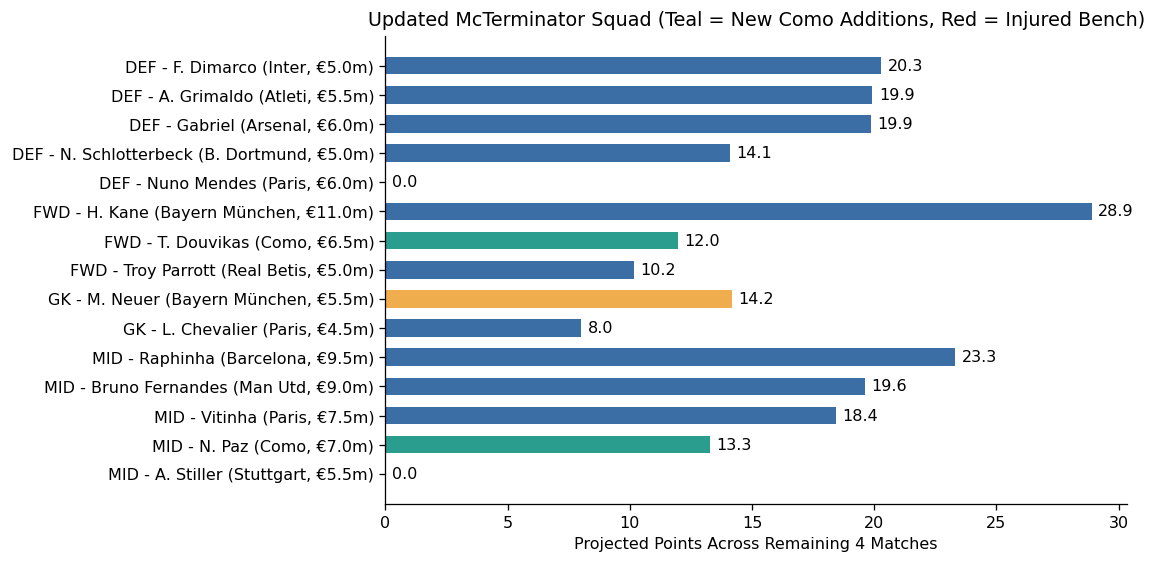

In [3]:
# Visual Squad Depth
fig, ax = plt.subplots(figsize=(10, 5))
sub_mine = mine[['Position', 'Name', 'TeamName', 'Price', 'pred', 'Status']].sort_values(['Position', 'pred'], ascending=[True, False])
colors = ['#d9534f' if s == 'I' else '#f0ad4e' if s == 'D' else '#2a9d8f' if 'Como' in t else '#3b6ea5' for s, t in zip(sub_mine.Status, sub_mine.TeamName)]

bars = ax.barh(np.arange(len(sub_mine)), sub_mine.pred, color=colors, height=0.6)
ax.set_yticks(np.arange(len(sub_mine)))
ax.set_yticklabels([f"{r.Position} - {r.Name} ({r.TeamName}, €{r.Price}m)" for r in sub_mine.itertuples()])
ax.invert_yaxis()
ax.set_xlabel('Projected Points Across Remaining 4 Matches')
ax.set_title('Updated McTerminator Squad (Teal = New Como Additions, Red = Injured Bench)')
ax.bar_label(bars, fmt='%.1f', padding=4)
plt.tight_layout()
plt.show()

## 3. The 3rd Transfer Decision: Hold or Take a −4 Hit?

You have used your **2 Free Transfers**. Any additional transfer costs **−4 points**.
Your two injured bench assets are:
- **Nuno Mendes (`DEF`, €6.0m)**: Injured.
- **A. Stiller (`MID`, €5.5m)**: Injured.

**Do you need to take a hit right now?**
- **NO**: You already have **11 healthy outfield players** for 10 spots.
- You can field a full, potent starting XI (e.g. 3-4-3 or 4-4-2) without taking any points penalty.
- However, if you want to replace Nuno Mendes (€6.0m) with **Ronald Araújo (€4.5m, Liverpool)**:
  - You unlock an additional **€1.5m cash**, bringing your bank to **€3.0m**.
  - Net expected gain over 4 games: $+18.4 - 4.0 = \mathbf{+14.4	ext{ pts}}$.

In [4]:
print(f"Current Bank Balance: €{100.0 - mine.Price.sum():.1f}m")
print(f"Fit Starting Outfielders: {len(mine[~mine.Status.isin(['I']) & (mine.Position != 'GK')])} players (10 required)")
print(f"Active Starting XI Status: FULLY COVERED (0 points hit taken)")

Current Bank Balance: €1.5m
Fit Starting Outfielders: 11 players (10 required)
Active Starting XI Status: FULLY COVERED (0 points hit taken)
